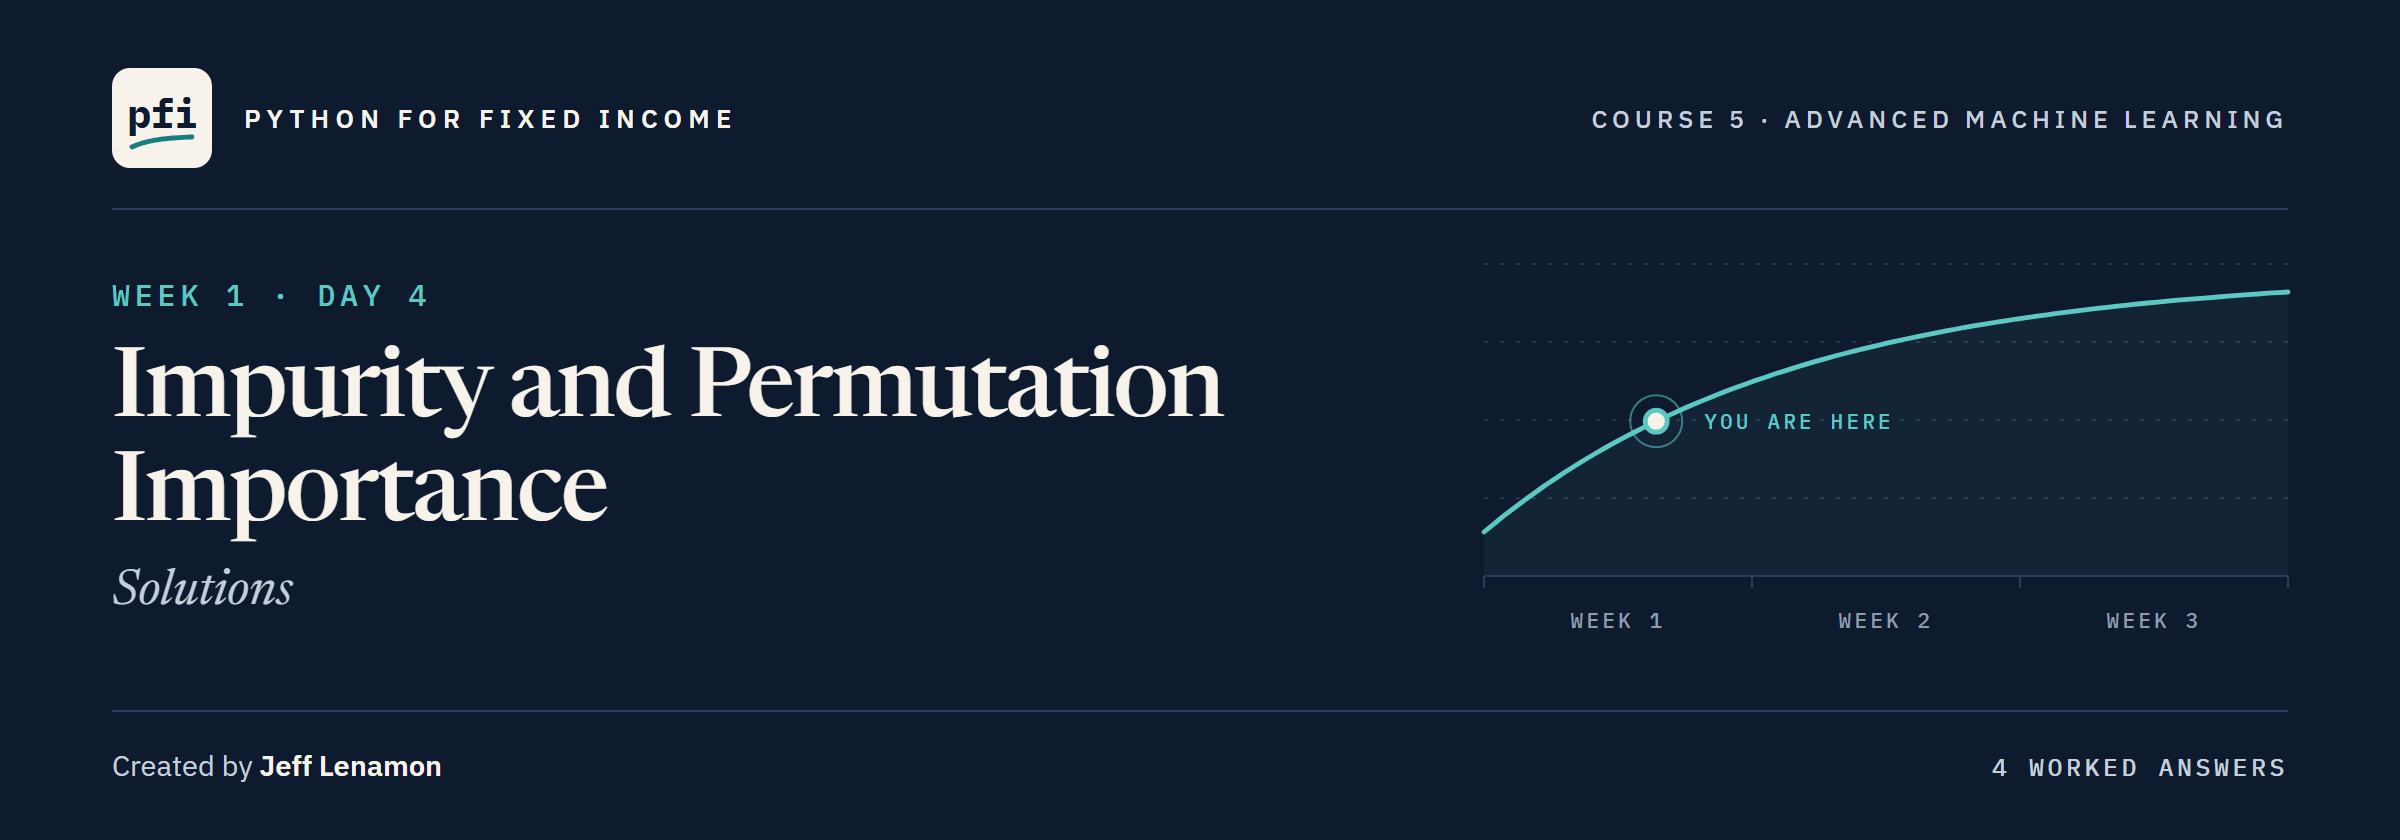

# Impurity and Permutation Importance: Solutions

Week 1, Day 4. The full notebook with every exercise worked. Try each one yourself first.

**Data:** `credit_card_default.csv`, 30,000 card accounts in Taiwan in 2005: **real**, UCI Machine Learning Repository dataset 350, CC BY 4.0. Citation: Yeh, I. (2009). Default of Credit Card Clients [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C55S3H.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week1/day4/04_impurity_and_permutation_importance_solutions.ipynb)

# Problem Statement

## Business Context

Day 3's forest ranks the validation accounts well, and a credit committee asks the next question: which columns does it lean on?
Course 4's Day 9 read two importances off one pruned tree, and they disagreed.
Before the desk quotes either for a forest, it tests them on a column whose worth is known in advance.
It plants a column of random numbers beside the 19 real ones and asks each measure to find it.
The accounts are real, from Taiwan in 2005, so they describe consumer credit there and then, not US credit today.
The four person columns are never features, so no importance is ever read for them.

## Objectives

Rank a forest's columns by impurity and by permutation importance, and plant a column of random numbers to test each measure.
Take impurity importance apart split by split, shuffle related columns one at a time and as a group, and compare shuffles on training and validation rows.

## Data Dictionary

`credit_card_default.csv`, one row per account:

1. `LIMIT_BAL`: credit limit, NT dollars
2. `PAY_0`, `PAY_2` to `PAY_6`: repayment status, September back to April 2005, where -1 is paid on time, 1 to 9 is months late, and -2 and 0 are undocumented (used as numbers, a modelling choice, as in Course 4)
3. `BILL_AMT1` to `BILL_AMT6`: the bill, NT dollars, September back to April
4. `PAY_AMT1` to `PAY_AMT6`: the amount paid, NT dollars, September back to April
5. `default payment next month`: 1 if the account defaulted the following month, **the target**
6. `ID`, `SEX`, `EDUCATION`, `MARRIAGE`, `AGE`: never used
7. `noise`: added today, a random number for every account, unrelated to anything in the file

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, and two dropdowns
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# to split the accounts
from sklearn.model_selection import train_test_split

# the forest, its scores, and the shuffles that measure what a column is worth to it
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.inspection import permutation_importance

# one look for every chart, and four decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:.4f}".format)

# Loading the Data

## Reading the Card File

In [3]:
# the 30,000 accounts; the target's name has spaces, so we keep it in a variable
card = pd.read_csv(DATA + "credit_card_default.csv")
TARGET = "default payment next month"

## Choosing the 19 Feature Columns

In [4]:
# every column except the ID, the four person columns and the target
X = card.drop(columns=["ID", "SEX", "EDUCATION", "MARRIAGE", "AGE", TARGET])
y = card[TARGET]
print(len(X.columns), "features")

19 features


# Data Overview

## Checking the Shape and the Default Share

In [5]:
# rows and columns, and how many accounts defaulted
print(card.shape)
print("Defaults:", y.sum(), " Share:", round(y.mean() * 100, 2), "percent")

(30000, 25)
Defaults: 6636  Share: 22.12 percent


**The file Course 4 used, unchanged, so we split it the same way.**

# Data Preparation for Modeling

## Course 4's Split

In [6]:
# Course 4's split: a fifth of the accounts to test, then a quarter of the rest to validation, defaults spread evenly
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_valid, y_train, y_valid = train_test_split(X_rest, y_rest, test_size=0.25, stratify=y_rest, random_state=SEED)
print("Training:", len(X_train), " Validation:", len(X_valid), " Test:", len(X_test))

Training: 18000  Validation: 6000  Test: 6000


Training rows fit the forest, validation rows report on it, and the test rows are never scored in Course 5.

## Planting a Column of Random Numbers

`rng.normal(size=n)` draws n numbers from a normal distribution with mean 0 and standard deviation 1.

In [7]:
# one generator, seeded, for every random draw in this notebook
rng = np.random.default_rng(SEED)

# a random number for every training account, then for every validation account
X_train["noise"] = rng.normal(size=len(X_train))
X_valid["noise"] = rng.normal(size=len(X_valid))
COLUMNS = list(X_train.columns)
print(len(COLUMNS), "columns, the last one:", COLUMNS[-1])

20 columns, the last one: noise


## Checking the Planted Column

Q. Does `noise` carry anything about default?

In [8]:
# its mean and spread, its correlation with default, and its mean for paid (0) and defaulted (1) accounts
print("Mean:", round(X_train["noise"].mean(), 4), " Standard deviation:", round(X_train["noise"].std(), 4))
print("Correlation with default:", round(X_train["noise"].corr(y_train), 4))
print(X_train["noise"].groupby(y_train).mean().round(4))

Mean: -0.0016  Standard deviation: 1.0035
Correlation with default: -0.0086
default payment next month
0    0.0030
1   -0.0178
Name: noise, dtype: float64


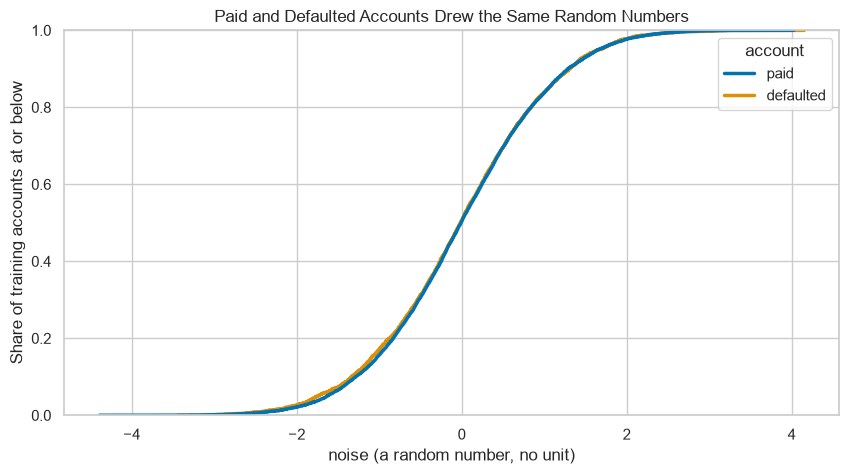

In [9]:
# the share of training accounts at or below each noise value, paid against defaulted
outcome = y_train.map({0: "paid", 1: "defaulted"}).rename("account")
sns.ecdfplot(x=X_train["noise"], hue=outcome, linewidth=2.5)
plt.xlabel("noise (a random number, no unit)")
plt.ylabel("Share of training accounts at or below")
plt.title("Paid and Defaulted Accounts Drew the Same Random Numbers")
plt.show()

Mean -0.0016, standard deviation 1.0035, correlation with default -0.0086.

Paid accounts average 0.0030 and defaulted accounts -0.0178, and the two curves lie on top of each other.

Knowing an account's noise says nothing about whether it defaulted.

**The planted column knows nothing about default, so a measure worth trusting puts it at the bottom.**

# Model Building

## A Forest of 200 Full Trees

Day 3's default forest: 200 trees grown in full, each split choosing among a random handful of the columns, now 4 of 20.

In [10]:
# Day 3's default forest, fitted on the 20 columns, noise included
forest = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1).fit(X_train, y_train)

# its output for each validation account, and ROC AUC on the validation and the training rows
valid_output = forest.predict_proba(X_valid)[:, 1]
fitted_auc = roc_auc_score(y_valid, valid_output)
print("Validation ROC AUC:", round(fitted_auc, 4))
print("Training ROC AUC:", round(roc_auc_score(y_train, forest.predict_proba(X_train)[:, 1]), 4))

Validation ROC AUC: 0.7667
Training ROC AUC: 1.0


In [11]:
# how big the trees grew: leaves and depth, averaged over the 200
print("Leaves per tree:", round(np.mean([tree.get_n_leaves() for tree in forest.estimators_])))
print("Depth per tree:", round(np.mean([tree.get_depth() for tree in forest.estimators_])))

Leaves per tree: 2507
Depth per tree: 43


Validation ROC AUC 0.7667: the forest ranks unseen accounts well.

Training ROC AUC 1.0: each tree grows about 2,507 leaves, 43 questions deep, and hands its training accounts back, which matters below.

**A strong forest on unseen accounts. Next: the columns it leans on.**

# Impurity Importance

Course 4's Day 9 defined it: each column's share of all the Gini decrease the tree's questions made on the training rows.
A forest's `.feature_importances_` is that share averaged over its 200 trees.

**Predict 1**

Q. Of the 20 columns, where will `noise` rank by impurity importance? Write down a number.

## The Forest's Own Ranking

In [12]:
# each column's impurity importance, largest first, and the planted column's rank
impurity = pd.Series(forest.feature_importances_, index=COLUMNS).sort_values(ascending=False)
print("noise ranks", int(impurity.rank(ascending=False)["noise"]), "of 20")
impurity.head(6)

noise ranks 2 of 20


PAY_0       0.0995
noise       0.0943
BILL_AMT1   0.0620
LIMIT_BAL   0.0606
BILL_AMT2   0.0556
BILL_AMT3   0.0532
dtype: float64

Random numbers rank second, 0.0943 against `PAY_0`'s 0.0995, ahead of every other real column.

None of the five other repayment status columns reaches the top six.

**If random numbers rank second, impurity importance measures something other than what the forest needs on new accounts. We measure that need directly.**

# Permutation Importance

![Six validation accounts with three columns, LIMIT_BAL, PAY_0 and BILL_AMT1; on the right the same six with only the PAY_0 values dealt to the accounts in a new order; the same forest scores both tables, and the fall in ROC AUC between the two is PAY_0's permutation importance](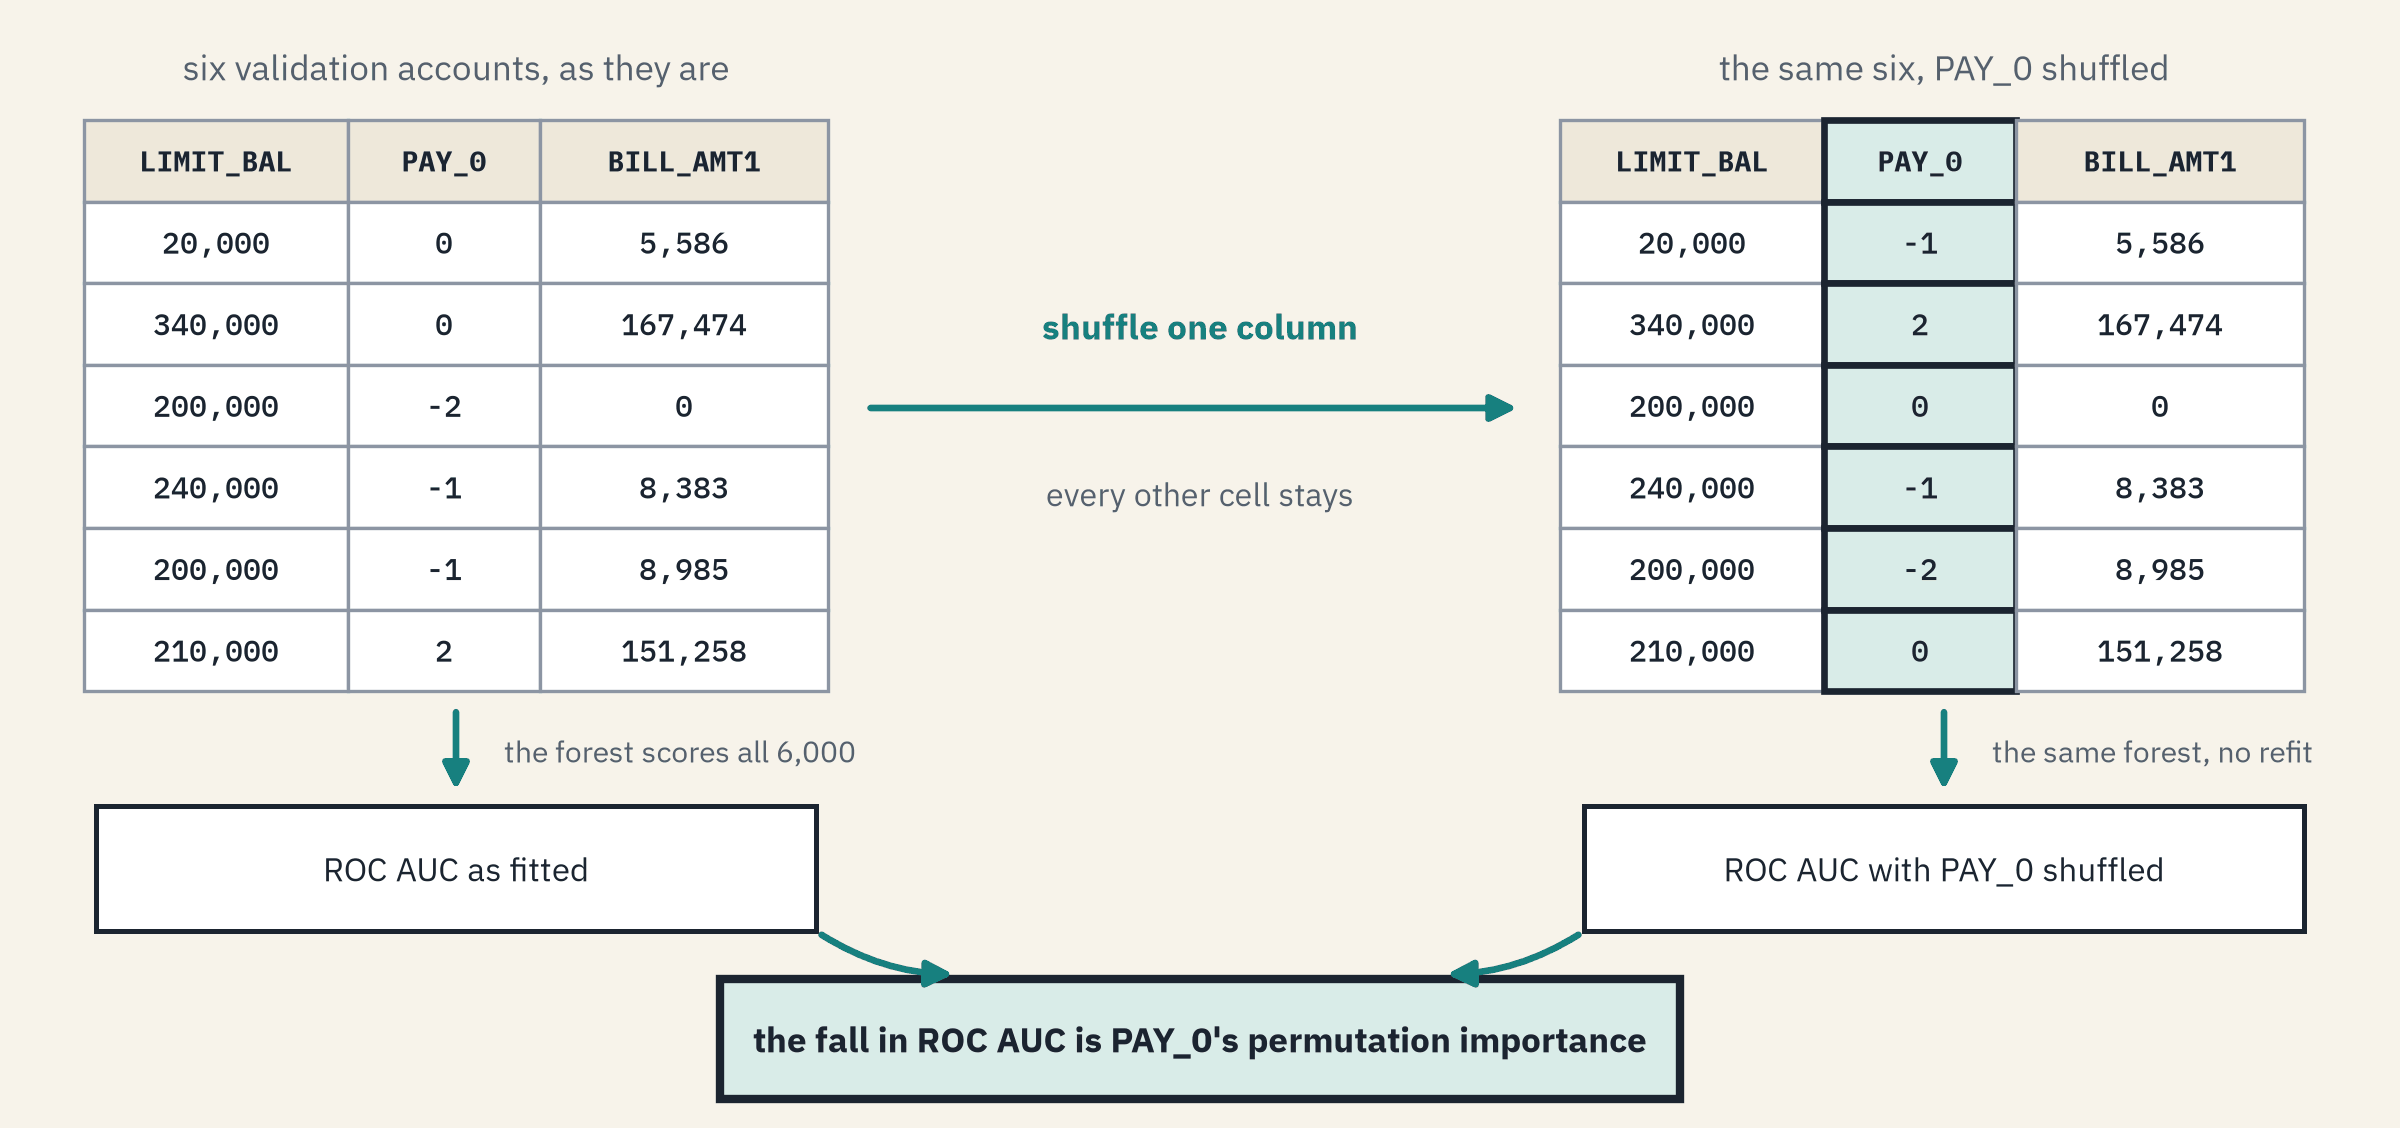)

**Permutation importance** shuffles one column's values among the validation accounts, scores the same forest again, and reads the fall in ROC AUC.
There is no refit.

## Shuffling One Column

`.sample(frac=1, random_state=SEED)` draws every value once in a random order: a shuffle.
`.to_numpy()` drops the index, so pandas does not put the values back in their old rows.

In [13]:
# the forest's output for the validation rows with one column's values shuffled among the accounts
def shuffled_output(column):
    shuffled = X_valid.copy()
    shuffled[column] = X_valid[column].sample(frac=1, random_state=SEED).to_numpy()
    return forest.predict_proba(shuffled)[:, 1]

print("As fitted:", round(fitted_auc, 4), " PAY_0 shuffled:", round(roc_auc_score(y_valid, shuffled_output("PAY_0")), 4))

As fitted: 0.7667  PAY_0 shuffled: 0.6957


In [14]:
# both ROC curves on one grid of false positive rates (Course 3's np.interp), the area between them shaded
def draw_shuffle(column, ax):
    grid = np.linspace(0, 1, 501)
    fpr, tpr, thresholds = roc_curve(y_valid, valid_output)
    fitted = np.interp(grid, fpr, tpr)
    output = shuffled_output(column)
    fpr, tpr, thresholds = roc_curve(y_valid, output)
    shuffled = np.interp(grid, fpr, tpr)
    ax.plot(grid, fitted, linewidth=2.5, label="as fitted")
    ax.plot(grid, shuffled, linewidth=2.5, label=column + " shuffled")
    ax.fill_between(grid, shuffled, fitted, color="C1", alpha=0.3, label="ROC AUC lost")
    ax.plot([0, 1], [0, 1], color="black", linestyle=":")
    ax.set(xlabel="False positive rate", ylabel="True positive rate (recall)")
    ax.set_title(f"{column} Shuffled: ROC AUC Lost {fitted_auc - roc_auc_score(y_valid, output):.4f}")
    ax.legend(loc="lower right")

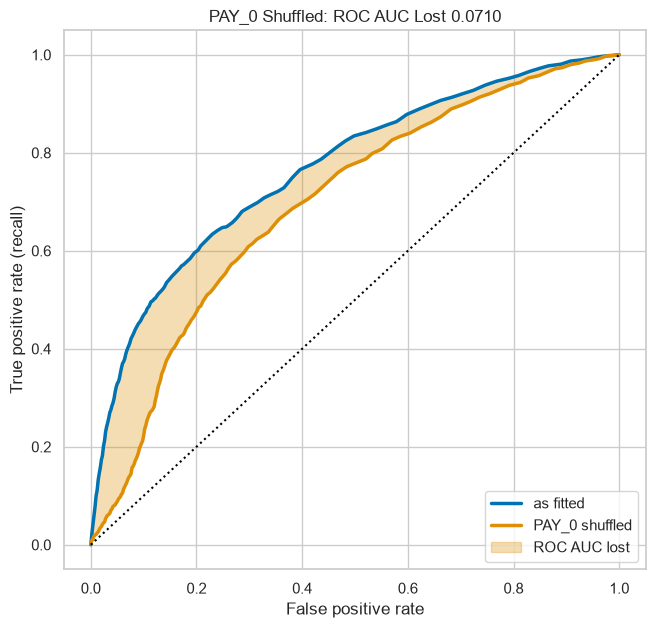

In [15]:
# PAY_0 shuffled
fig, ax = plt.subplots(figsize=(7.5, 7))
draw_shuffle("PAY_0", ax)
plt.show()

ROC AUC falls from 0.7667 to 0.6957 with `PAY_0` scrambled, and the curve sinks toward the diagonal, where a coin toss sits.

The shaded area is the ROC AUC lost: what the forest leans on `PAY_0` for, on accounts it never saw.

### Try Any Column

Pick a column and watch the shaded area.

In [16]:
# your turn: pick a column from the dropdown
def try_column(column="PAY_0"):
    fig, ax = plt.subplots(figsize=(7.5, 7))
    draw_shuffle(column, ax)
    plt.show()

interact(try_column, column=COLUMNS);

interactive(children=(Dropdown(description='column', index=1, options=('LIMIT_BAL', 'PAY_0', 'PAY_2', 'PAY_3',…

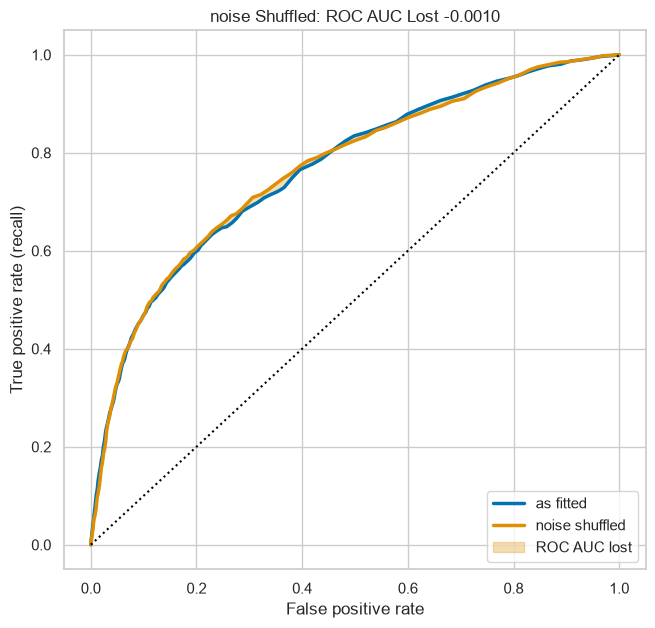

In [17]:
# the dropdown set to noise, drawn as a still picture (dropdowns do not run on GitHub)
fig, ax = plt.subplots(figsize=(7.5, 7))
draw_shuffle("noise", ax)
plt.show()

With `noise` shuffled the two curves lie on top of each other, and ROC AUC "falls" by -0.0010: no area at all.

## Ten Shuffles for Every Column

One shuffle is one draw of luck.
`permutation_importance` (Course 4's Day 9) shuffles every column `n_repeats` times: `.importances_mean` is the mean fall, and `.importances_std` its standard deviation over the shuffles.

In [18]:
# every column shuffled ten times on the validation rows, the fall in ROC AUC each time
perm = permutation_importance(forest, X_valid, y_valid, scoring="roc_auc", n_repeats=10, random_state=SEED, n_jobs=1)

# both measures in one table, largest permutation importance first
importance = pd.DataFrame({"impurity": forest.feature_importances_, "permutation": perm.importances_mean,
                           "sd": perm.importances_std}, index=COLUMNS).sort_values("permutation", ascending=False)
importance.head(6)

,impurity,permutation,sd
PAY_0,0.0995,0.0690,0.0040
LIMIT_BAL,0.0606,0.0284,0.0041
PAY_AMT1,0.0519,0.0166,0.0027
PAY_2,0.0471,0.0117,0.0018
PAY_AMT2,0.0490,0.0081,0.0021
PAY_3,0.0283,0.0047,0.0020


In [19]:
# the planted column's row, its rank, and how many columns lose less than nothing
print(importance.loc["noise"].round(4).to_dict())
print("noise ranks", int(importance["permutation"].rank(ascending=False)["noise"]), "of 20")
print("Columns below zero:", (importance["permutation"] < 0).sum())

{'impurity': 0.0943, 'permutation': -0.0008, 'sd': 0.0021}
noise ranks 16 of 20
Columns below zero: 6


`PAY_0` comes first again, 0.0690, then `LIMIT_BAL` 0.0284, `PAY_AMT1` 0.0166 and `PAY_2` 0.0117.

`noise` ranks 16th, at -0.0008 with a standard deviation of 0.0021, and 6 columns fall below zero.

## The Noise Band

A column of random numbers is worth nothing, so its spread over ten shuffles shows how far luck alone moves a fall.
The **noise band** is zero plus or minus two of the noise column's standard deviations.

In [20]:
# the noise band, and the columns whose fall clears it
band = 2 * importance.loc["noise", "sd"]
print("Noise band: plus or minus", round(band, 4))
print("Above it:", list(importance.index[importance["permutation"] > band]))

# one colour per column for the charts: noise orange, the rest blue
colours = ["C1" if name == "noise" else "C0" for name in importance.index]

Noise band: plus or minus 0.0042
Above it: ['PAY_0', 'LIMIT_BAL', 'PAY_AMT1', 'PAY_2', 'PAY_AMT2', 'PAY_3', 'PAY_4']


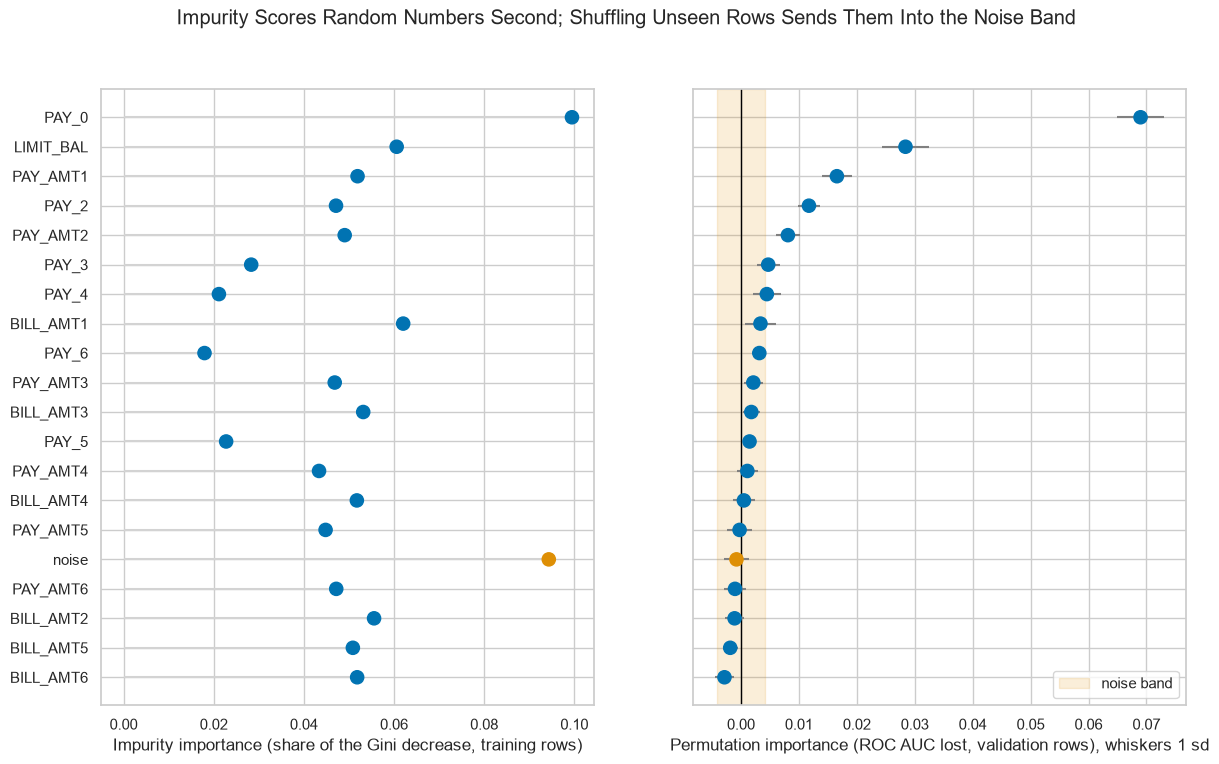

In [21]:
# the showpiece: both measures in one column order, noise in orange, the noise band shaded
fig, axes = plt.subplots(1, 2, figsize=(14, 8), sharey=True)
axes[0].hlines(importance.index, 0, importance["impurity"], color="lightgray")
axes[0].scatter(importance["impurity"], importance.index, color=colours, s=90, zorder=3)
axes[1].axvspan(-band, band, color="C1", alpha=0.15, label="noise band")
axes[1].axvline(0, color="black", linewidth=1)
axes[1].hlines(importance.index, importance["permutation"] - importance["sd"], importance["permutation"] + importance["sd"], color="gray")
axes[1].scatter(importance["permutation"], importance.index, color=colours, s=90, zorder=3)
axes[0].set_xlabel("Impurity importance (share of the Gini decrease, training rows)")
axes[1].set_xlabel("Permutation importance (ROC AUC lost, validation rows), whiskers 1 sd")
axes[0].invert_yaxis()
axes[1].legend(loc="lower right")
fig.suptitle("Impurity Scores Random Numbers Second; Shuffling Unseen Rows Sends Them Into the Noise Band")
plt.show()

On the left the orange dot sits further right than every real column but `PAY_0`; on the right it sits inside the band, plus or minus 0.0042.

Only 7 columns clear the band; the other 13 sit inside it, so their order among themselves is not information.

`BILL_AMT1`, `BILL_AMT2` and `BILL_AMT3` rank 3rd, 5th and 6th by impurity and sit inside the band by permutation.

### Interpretation of a Permutation Importance

It is the fall in validation ROC AUC when the forest loses one column's link to the outcome, every other column untouched.

It says how much this forest leans on the column for unseen accounts: an association in this file.

It is not a direction and not a cause: a shuffle breaks the column, and says nothing of what another value would do.

**Permutation importance on unseen rows sends the random column to zero. Next: why impurity importance did not.**

# Why Impurity Rewards Noise

## Distinct Values

Q. What does `noise` have that `PAY_0` lacks?

In [22]:
# how many different values each column takes on the training rows
importance["distinct"] = X_train.nunique()
importance["distinct"].sort_values(ascending=False)

noise        18000
BILL_AMT1    14404
BILL_AMT2    14207
BILL_AMT3    13976
BILL_AMT4    13747
BILL_AMT5    13382
BILL_AMT6    13167
PAY_AMT1      5717
PAY_AMT2      5688
PAY_AMT3      5417
PAY_AMT4      5030
PAY_AMT6      4988
PAY_AMT5      4958
LIMIT_BAL       78
PAY_2           11
PAY_0           11
PAY_3           11
PAY_4           11
PAY_5           10
PAY_6           10
Name: distinct, dtype: int64

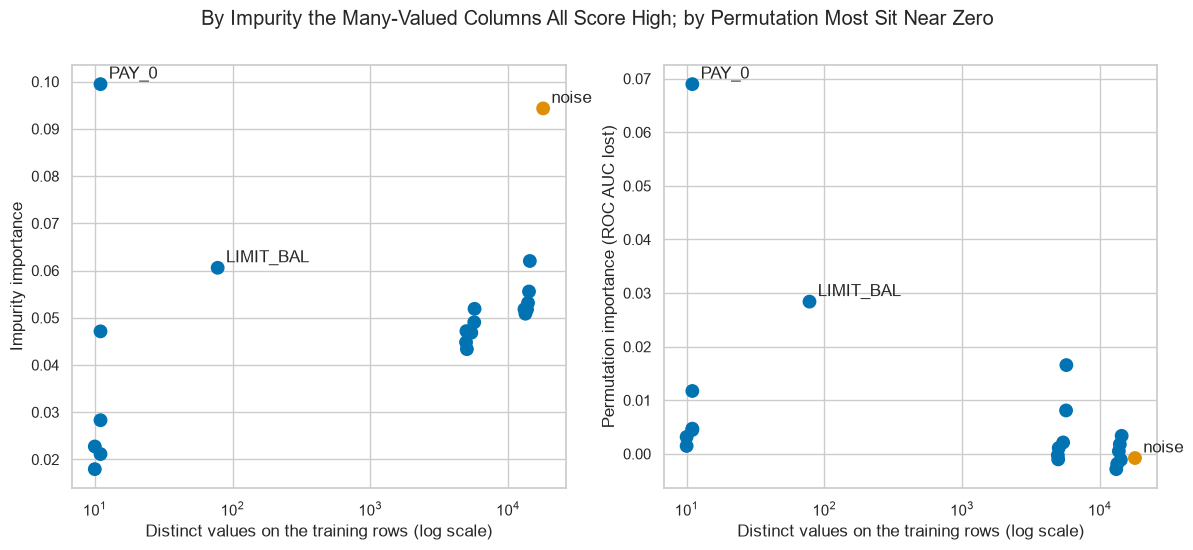

In [23]:
# distinct values against each importance, one dot per column, the distinct values on a log axis
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True)
labels = ["Impurity importance", "Permutation importance (ROC AUC lost)"]
for ax, measure, label in zip(axes, ["impurity", "permutation"], labels):
    ax.scatter(importance["distinct"], importance[measure], color=colours, s=80)
    for name in ["noise", "PAY_0", "LIMIT_BAL"]:
        ax.annotate(name, (importance.loc[name, "distinct"], importance.loc[name, measure]),
                    textcoords="offset points", xytext=(6, 4))
    ax.set_xscale("log")
    ax.set(xlabel="Distinct values on the training rows (log scale)", ylabel=label)
fig.suptitle("By Impurity the Many-Valued Columns All Score High; by Permutation Most Sit Near Zero")
plt.show()

`noise` has 18,000 values, one per training account; the bills 13,167 to 14,404, the payments 4,958 to 5,717, `LIMIT_BAL` 78, and the status columns 10 or 11.

By impurity the many-valued columns sit high; by permutation they sit near zero, bar two payment amounts.

## Counting the Questions

Every node of a tree asks about one column: `.tree_.feature` (Day 1) holds its number, -2 at a leaf.
`.tree_.n_node_samples` (Course 4's Day 9) holds the training accounts that reach each node.
`np.concatenate` joins the 200 trees' arrays into one.

In [24]:
# every node of every tree: the column it asks about and the training accounts that reach it
features = np.concatenate([tree.tree_.feature for tree in forest.estimators_])
accounts = np.concatenate([tree.tree_.n_node_samples for tree in forest.estimators_])

# one row per split, the leaves left out
splits = pd.DataFrame({"column": np.array(COLUMNS)[features[features >= 0]], "accounts": accounts[features >= 0]})
print("Splits in the 200 trees:", len(splits))

Splits in the 200 trees: 501277


In [25]:
# splits per column, most first, and each column's share of all the splits
split_counts = splits["column"].value_counts()
split_table = pd.DataFrame({"splits": split_counts, "percent": split_counts / len(splits) * 100})
split_table.loc[["noise", "LIMIT_BAL", "BILL_AMT1", "PAY_0"]]

,splits,percent
column,,
noise,59289,11.8276
LIMIT_BAL,38950,7.7702
BILL_AMT1,36494,7.2802
PAY_0,9256,1.8465


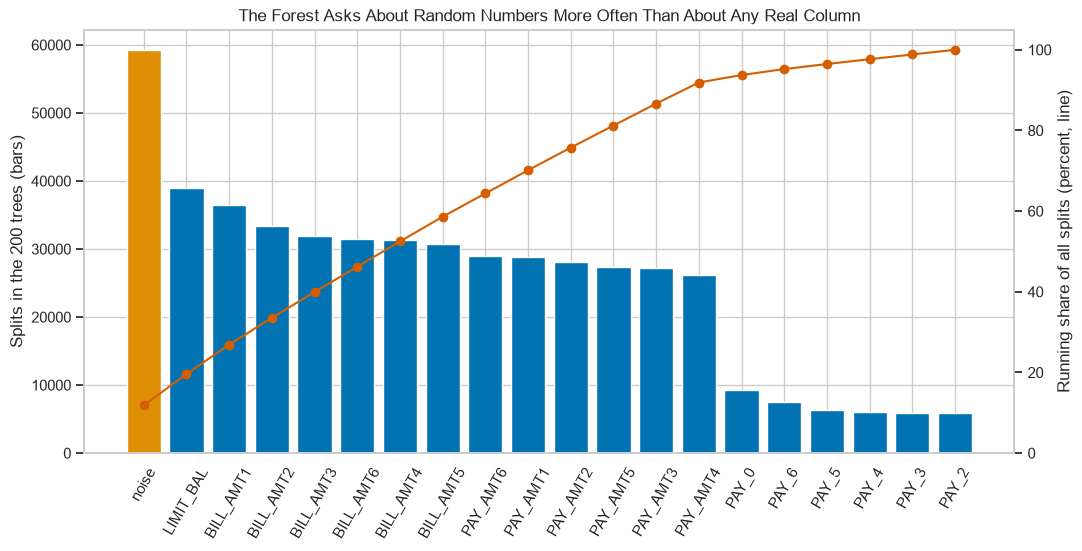

In [26]:
# a Pareto chart: splits per column as sorted bars, the running share of all splits as a line on a second axis
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.bar(split_counts.index, split_counts.values, color=["C1" if name == "noise" else "C0" for name in split_counts.index])
ax.tick_params(axis="x", rotation=60)
ax.set_ylabel("Splits in the 200 trees (bars)")
share_ax = ax.twinx()
share_ax.plot(split_counts.index, split_counts.cumsum() / len(splits) * 100, color="C3", marker="o")
share_ax.set(ylim=(0, 105), ylabel="Running share of all splits (percent, line)")
share_ax.grid(False)
ax.set_title("The Forest Asks About Random Numbers More Often Than About Any Real Column")
plt.show()

A **Pareto chart** sorts the bars from tallest and adds the running share, so the few that make up most of the total stand out.

`noise` is asked about 59,289 times, 11.8 percent of the 501,277 splits, more than any real column.

`PAY_0`, the column the forest leans on most, is asked about far less often than any bill or payment amount.

The line passes 90 percent once the bills, the payments, `LIMIT_BAL` and `noise` are in, so the six status columns share about the last 8 percent of the splits.

## Where the Questions Are Asked

In [27]:
# the median accounts at a split, and the share of splits made on 10 accounts or fewer
for name in ["noise", "PAY_0"]:
    sizes = splits.loc[splits["column"] == name, "accounts"]
    print(name, " median accounts:", sizes.median(), " splits on 10 or fewer:", round((sizes <= 10).mean() * 100), "percent")

noise  median accounts: 9.0  splits on 10 or fewer: 55 percent
PAY_0  median accounts: 19.0  splits on 10 or fewer: 37 percent


`element="step", fill=False` draws each histogram as an outline, and `stat="percent", common_norm=False` makes each column's bars add up to 100.
`log_scale=True` spaces the x axis by powers of ten.

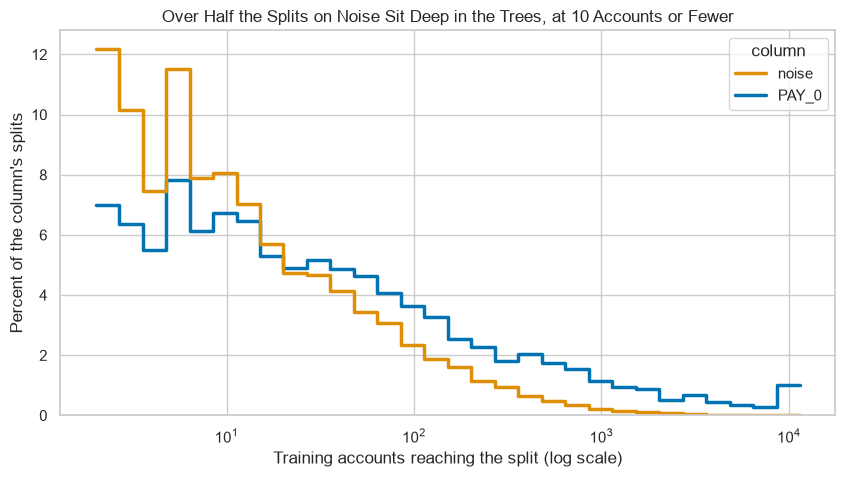

In [28]:
# accounts at each split on a log axis: splits on noise against splits on PAY_0
pair = splits[splits["column"].isin(["noise", "PAY_0"])]
sns.histplot(data=pair, x="accounts", hue="column", hue_order=["noise", "PAY_0"], palette=["C1", "C0"], log_scale=True,
             element="step", fill=False, stat="percent", common_norm=False, bins=30, linewidth=2.5)
plt.xlabel("Training accounts reaching the split (log scale)")
plt.ylabel("Percent of the column's splits")
plt.title("Over Half the Splits on Noise Sit Deep in the Trees, at 10 Accounts or Fewer")
plt.show()

A split on `noise` sees a median of 9 accounts, a split on `PAY_0` 19.

55 percent of the `noise` splits sit in nodes of 10 accounts or fewer, against 37 percent for `PAY_0`, whose splits reach up to the root.

### Interpretation of the Credit

A full tree keeps splitting until each leaf is pure, so its last splits separate a few training accounts from each other.

Down there, a column with a different value for every account can always split the last few, and each split earns a sliver of Gini decrease.

Tens of thousands of slivers add up to the share that ranked random numbers near the top.

## Bigger Leaves

Day 3's `min_samples_leaf` stops a tree splitting once a leaf would hold fewer accounts than that.

**Predict 2**

Q. With leaves of at least 20 accounts, where will `noise` rank by impurity importance? Write down a number.

In [29]:
# forests whose leaves hold at least 5, 20, 50 and 100 training accounts, beside the full trees
leaf_sizes = [1, 5, 20, 50, 100]
leaf_forests = {1: forest}
for leaf in leaf_sizes[1:]:
    leaf_forests[leaf] = RandomForestClassifier(n_estimators=200, min_samples_leaf=leaf, random_state=SEED,
                                                n_jobs=1).fit(X_train, y_train)

In [30]:
# for each leaf size: noise's impurity importance and rank, and the forest's validation ROC AUC
leaf_impurity = pd.DataFrame({leaf: leaf_forests[leaf].feature_importances_ for leaf in leaf_sizes}, index=COLUMNS)
leaf_ranks = leaf_impurity.rank(ascending=False).astype(int)
leaf_auc = {leaf: roc_auc_score(y_valid, leaf_forests[leaf].predict_proba(X_valid)[:, 1]) for leaf in leaf_sizes}
pd.DataFrame({"noise impurity": leaf_impurity.loc["noise"], "noise rank": leaf_ranks.loc["noise"],
              "validation ROC AUC": pd.Series(leaf_auc)})

,noise impurity,noise rank,validation ROC AUC
1,0.0943,2,0.7667
5,0.0611,3,0.7808
20,0.0333,10,0.7861
50,0.0168,16,0.7861
100,0.0084,20,0.7838


In [31]:
# one forest's impurity importances as bars, noise in orange
def draw_leaf(leaf, ax):
    ordered = leaf_impurity[leaf].sort_values()
    ax.barh(ordered.index, ordered.values, color=["C1" if name == "noise" else "C0" for name in ordered.index])
    ax.set_xlabel("Impurity importance (share of the Gini decrease)")
    ax.set_title(f"Leaves of {leaf} or More: noise Ranks {leaf_ranks.loc['noise', leaf]} of 20, "
                 f"Validation ROC AUC {leaf_auc[leaf]:.4f}")

In [32]:
# your turn: pick a leaf size from the dropdown and watch the orange bar
def try_leaf(leaf=1):
    fig, ax = plt.subplots(figsize=(10, 7))
    draw_leaf(leaf, ax)
    plt.show()

interact(try_leaf, leaf=leaf_sizes);

interactive(children=(Dropdown(description='leaf', options=(1, 5, 20, 50, 100), value=1), Output()), _dom_clas…

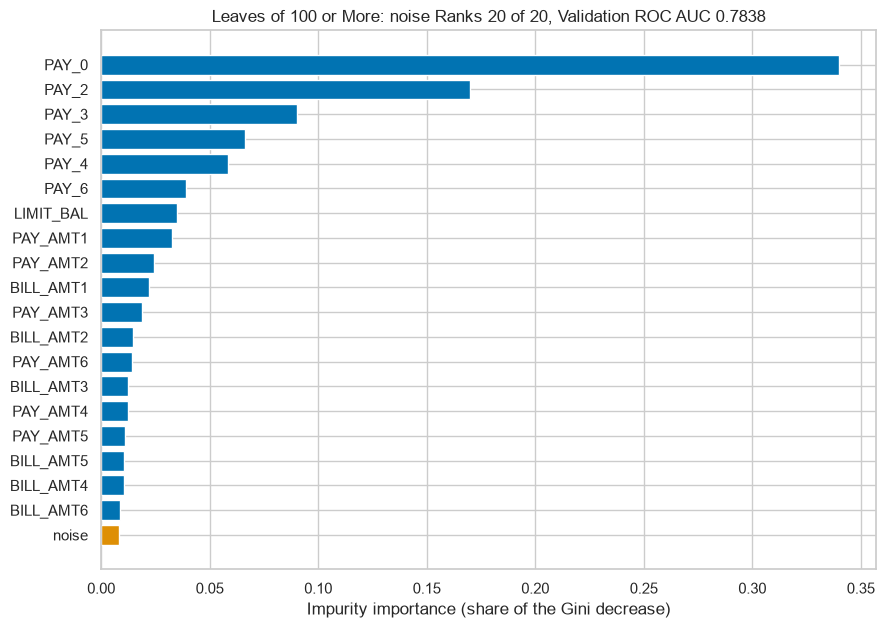

In [33]:
# the dropdown set to 100-account leaves, drawn as a still picture (dropdowns do not run on GitHub)
fig, ax = plt.subplots(figsize=(10, 7))
draw_leaf(100, ax)
plt.show()

`noise` slides from 2nd to 3rd, 10th, 16th and last as the leaves grow to 5, 20, 50 and 100 accounts.

Validation ROC AUC rises from 0.7667 to 0.7861 at 20 and 50 accounts, then eases to 0.7838 at 100.

**Impurity importance credits every split on the training rows, so full trees hand credit to the column best at memorising. Bigger leaves shrink that credit; only a test on unseen rows removes it.**

# Correlated Columns Share Importance

## Six Bills That Move Together

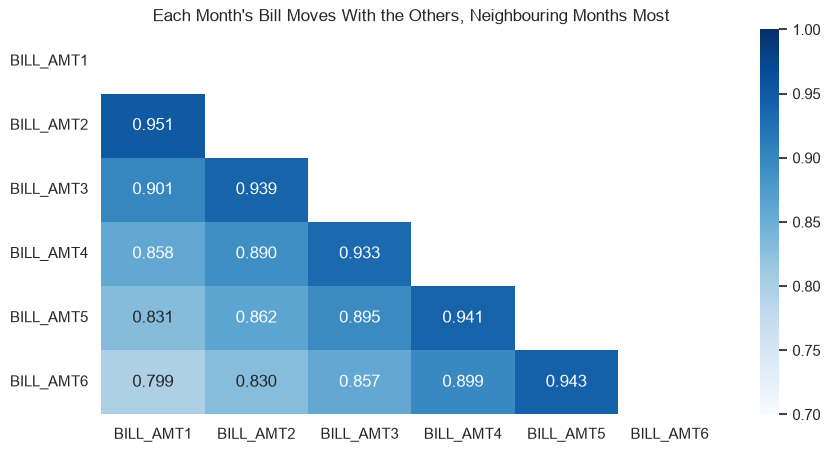

In [34]:
# the six bills' correlations on the training rows, the lower triangle only
bills = ["BILL_AMT1", "BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6"]
bill_corr = X_train[bills].corr()
sns.heatmap(bill_corr, mask=np.triu(np.ones_like(bill_corr, dtype=bool)), annot=True, fmt=".3f", cmap="Blues",
            vmin=0.7, vmax=1)
plt.grid(False)
plt.title("Each Month's Bill Moves With the Others, Neighbouring Months Most")
plt.show()

In [35]:
# each bill's permutation importance on its own, and the six added up
print(importance.loc[bills, "permutation"].round(4).to_dict())
print("Sum of the six:", round(importance.loc[bills, "permutation"].sum(), 4))

{'BILL_AMT1': 0.0034, 'BILL_AMT2': -0.0011, 'BILL_AMT3': 0.0018, 'BILL_AMT4': 0.0005, 'BILL_AMT5': -0.0019, 'BILL_AMT6': -0.0029}
Sum of the six: -0.0002


The bills correlate at 0.799 to 0.951, neighbouring months highest.

The single falls run from 0.0034 to -0.0029 and sum to -0.0002: shuffle one bill and the forest reads much the same from its neighbours.

**Predict 3**

Q. Shuffle all six bills together, with one row order for the six. How much validation ROC AUC will the forest lose? Write down a number.

## Shuffling the Six Together

In [36]:
# ten group shuffles: one random row order from the notebook's generator, applied to all six bills at once
group_drops = []
for k in range(10):
    shuffled = X_valid.copy()
    shuffled[bills] = X_valid[bills].iloc[rng.permutation(len(X_valid))].to_numpy()
    group_drops.append(fitted_auc - roc_auc_score(y_valid, forest.predict_proba(shuffled)[:, 1]))
print("Six bills together: mean fall", round(np.mean(group_drops), 4), " sd", round(np.std(group_drops), 4))

Six bills together: mean fall 0.0251  sd 0.0033


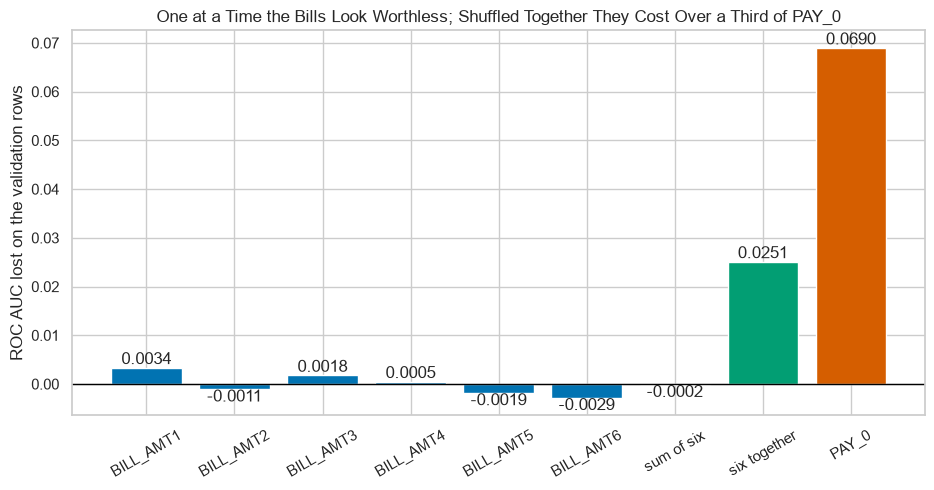

In [37]:
# the six single falls, their sum, the six together, and PAY_0 for scale
singles = importance.loc[bills, "permutation"]
heights = list(singles) + [singles.sum(), np.mean(group_drops), importance.loc["PAY_0", "permutation"]]
plt.figure(figsize=(11, 5))
bars = plt.bar(bills + ["sum of six", "six together", "PAY_0"], heights, color=["C0"] * 6 + ["gray", "C2", "C3"])
plt.bar_label(bars, fmt="%.4f")
plt.axhline(0, color="black", linewidth=1)
plt.xticks(rotation=30)
plt.ylabel("ROC AUC lost on the validation rows")
plt.title("One at a Time the Bills Look Worthless; Shuffled Together They Cost Over a Third of PAY_0")
plt.show()

Shuffled together the six cost 0.0251 (sd 0.0033), over a third of `PAY_0`'s 0.0690, where their single falls summed to -0.0002.

0.0251 sits far outside the noise band of plus or minus 0.0042, so luck alone does not give a fall this large.

**One at a time the bill amounts look worthless; together the forest leans on them. Shuffle related columns as a group before calling any of them unimportant.**

# Training Rows Against Validation Rows

**Predict 4**

The forest scores 1.0 on its own training rows.

Q. Shuffle on 6,000 of the training rows instead of the validation rows. Where will `noise` rank by permutation importance? Write down a number.

## Shuffling the Rows the Forest Was Fitted On

In [38]:
# the same ten shuffles on the first 6,000 training rows, the rows the forest was fitted on
train_perm = permutation_importance(forest, X_train.iloc[:6000], y_train.iloc[:6000], scoring="roc_auc", n_repeats=10,
                                    random_state=SEED, n_jobs=1)
importance["training"] = pd.Series(train_perm.importances_mean, index=COLUMNS)
print("noise ranks", int(importance["training"].rank(ascending=False)["noise"]), "of 20 on training rows")
importance[["permutation", "training"]].sort_values("training", ascending=False).head(6)

noise ranks 4 of 20 on training rows


,permutation,training
PAY_0,0.0690,0.0549
LIMIT_BAL,0.0284,0.0299
BILL_AMT1,0.0034,0.0081
noise,-0.0008,0.0081
PAY_AMT6,-0.0010,0.0046
PAY_AMT1,0.0166,0.0035


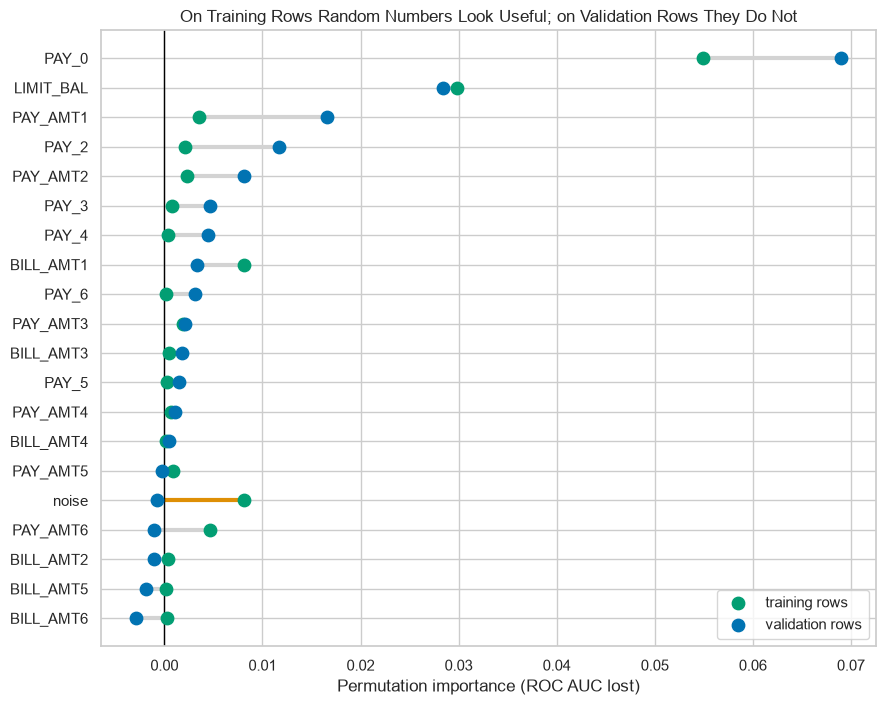

In [39]:
# a dumbbell per column: the fall on training rows against the fall on validation rows, noise's bar in orange
order = importance.sort_values("permutation")
fig, ax = plt.subplots(figsize=(10, 8))
ax.hlines(order.index, order["permutation"], order["training"], linewidth=3,
          color=["C1" if name == "noise" else "lightgray" for name in order.index])
ax.scatter(order["training"], order.index, s=80, color="C2", label="training rows", zorder=3)
ax.scatter(order["permutation"], order.index, s=80, color="C0", label="validation rows", zorder=3)
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Permutation importance (ROC AUC lost)")
ax.set_title("On Training Rows Random Numbers Look Useful; on Validation Rows They Do Not")
ax.legend(loc="lower right")
plt.show()

On training rows `noise` ranks 4th, at 0.0081, level with `BILL_AMT1` and behind only `PAY_0` and `LIMIT_BAL`.

Its orange bar is among the longest: from 16th on unseen rows to 4th on the rows the trees memorised.

### Interpretation of the Two Shuffles

On training rows a shuffle measures how much the forest used a column to fit those rows, noise included.

On validation rows it measures what the forest leans on for accounts it has never seen.

Only the second answers the committee's question.

## Four Views of One Forest

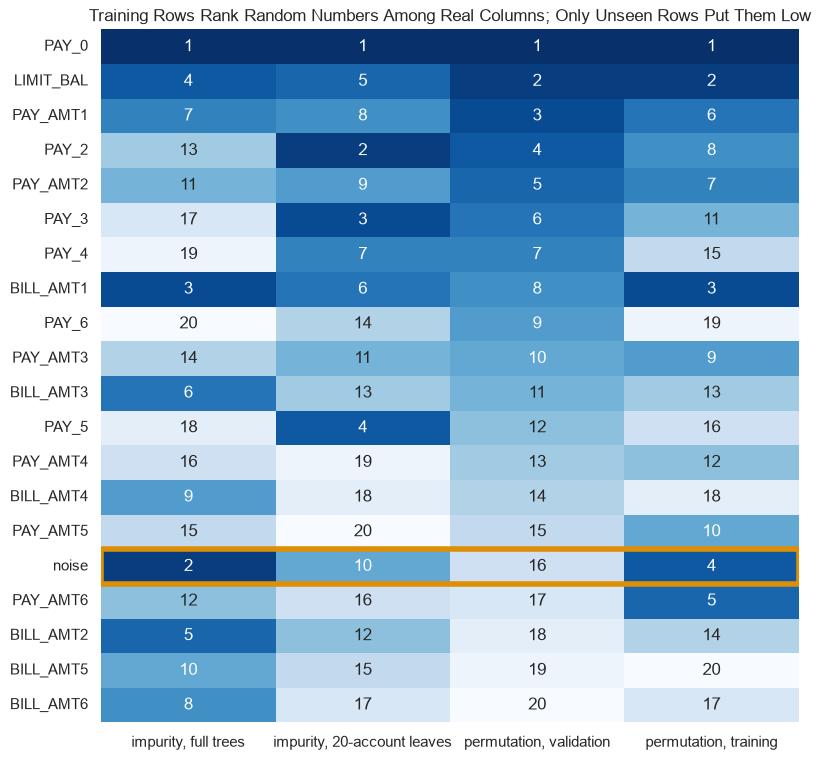

In [40]:
# each column's rank under four views, sorted by the validation shuffles, noise outlined in orange
views = pd.DataFrame({"impurity, full trees": impurity, "impurity, 20-account leaves": leaf_impurity[20],
                      "permutation, validation": importance["permutation"],
                      "permutation, training": importance["training"]})
ranks = views.rank(ascending=False).astype(int).sort_values("permutation, validation")
fig, ax = plt.subplots(figsize=(9, 9))
sns.heatmap(ranks, annot=True, fmt="d", cmap="Blues_r", cbar=False, ax=ax)
ax.add_patch(plt.Rectangle((0, ranks.index.get_loc("noise")), 4, 1, fill=False, edgecolor="C1", linewidth=4))
ax.set_title("Training Rows Rank Random Numbers Among Real Columns; Only Unseen Rows Put Them Low")
plt.show()

Read across the orange row: 2, 10, 16 and 4.

The three views scored on training rows place random numbers among the real columns; only shuffles on validation rows put them near the bottom.

**Ask the question on rows the model has never seen, with a column of random numbers beside the real ones.**

# Insights and Conclusion

Random numbers ranked 2nd of 20 by impurity importance, and 16th by permutation importance on validation rows, inside the noise band.

Impurity credit follows distinct values and deep splits: full trees asked about `noise` more than about any real column, mostly in nodes of a few accounts.

Bigger leaves pushed `noise` to 10th at 20 accounts and last at 100, and raised validation ROC AUC.

Related columns share importance: the six bills summed to -0.0002 one at a time and cost 0.0251 together.

Shuffled on training rows, `noise` climbed back to 4th.

Every importance here says what this forest leans on in this file, Taiwan in 2005, never a driver or a cause.

Week 2's boosters report importance too: LightGBM's default counts splits, the count drawn here (Day 9), and Day 14 adds SHAP values.

**Plant a column of random numbers, shuffle on unseen rows, and shuffle related columns together.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Read a forest's impurity importance and measure its permutation importance on validation rows.
* Plant a column of random numbers and read every importance against its noise band.
* Count a forest's splits by column and the accounts that reach each split.
* Shuffle related columns one at a time and as a group.
* Compare permutation importance on training and validation rows.

## Exercises

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [41]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**Importance in Average Precision**

Q. Run `permutation_importance` on `forest` and the validation rows with `scoring="average_precision"` and `n_repeats=3`. Store `PAY_0`'s mean fall in `ex1_pay0` and the rank of `noise` in `ex1_noise_rank`.

In [42]:
# three shuffles per column, each fall measured in validation average precision
ap_perm = permutation_importance(forest, X_valid, y_valid, scoring="average_precision", n_repeats=3,
                                 random_state=SEED, n_jobs=1)
ap_falls = pd.Series(ap_perm.importances_mean, index=COLUMNS)
ap_sd = pd.Series(ap_perm.importances_std, index=COLUMNS)
ex1_pay0 = float(ap_falls["PAY_0"])
ex1_noise_rank = int(ap_falls.rank(ascending=False)["noise"])
print(ex1_pay0, ex1_noise_rank, "noise:", round(ap_falls["noise"], 4), "sd", round(ap_sd["noise"], 4))

0.16421643320688536 5 noise: 0.0025 sd 0.0012


In [43]:
check("Exercise 1 PAY_0's fall in average precision", ex1_pay0, 0.16421643320688536)
check("Exercise 1 noise's rank", ex1_noise_rank, 5)

Exercise 1 PAY_0's fall in average precision: correct
Exercise 1 noise's rank: correct


In average precision `PAY_0` costs 0.1642, and `noise` ranks 5th at 0.0025 with a standard deviation of 0.0012.

That is just outside two standard deviations of zero.

Three shuffles give only a rough standard deviation, so a band built on them is rough too: rerun with `n_repeats=10` before reading anything into a column this close to its band.

### Exercise 2

**One Bill Instead of Six**

Q. Drop `BILL_AMT2` to `BILL_AMT6` from the training and validation rows and fit the same forest (200 trees, `random_state=SEED`, `n_jobs=1`). Store its validation ROC AUC in `ex2_auc`, and `BILL_AMT1`'s permutation importance (ROC AUC, `n_repeats=3`) in `ex2_bill1`.

In [44]:
# the rows without five of the six bills, and the same forest fitted on them
one_bill_train = X_train.drop(columns=bills[1:])
one_bill_valid = X_valid.drop(columns=bills[1:])
one_bill = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1).fit(one_bill_train, y_train)
ex2_auc = roc_auc_score(y_valid, one_bill.predict_proba(one_bill_valid)[:, 1])

# three shuffles per column on the validation rows
one_bill_perm = permutation_importance(one_bill, one_bill_valid, y_valid, scoring="roc_auc", n_repeats=3,
                                       random_state=SEED, n_jobs=1)
one_bill_falls = pd.Series(one_bill_perm.importances_mean, index=one_bill_valid.columns)
ex2_bill1 = float(one_bill_falls["BILL_AMT1"])
print(ex2_auc, ex2_bill1, "rank", int(one_bill_falls.rank(ascending=False)["BILL_AMT1"]), "of", len(one_bill_falls))

0.7691475391912139 0.008566127797386414 rank 5 of 15


In [45]:
check("Exercise 2 the validation ROC AUC", ex2_auc, 0.7691475391912139)
check("Exercise 2 BILL_AMT1's permutation importance", ex2_bill1, 0.008566127797386414)

Exercise 2 the validation ROC AUC: correct
Exercise 2 BILL_AMT1's permutation importance: correct


Without its five siblings the forest scores 0.7691 on validation rows, against 0.7667 with all six bills.

`BILL_AMT1` now costs 0.0086 when shuffled, 5th of 15, against 0.0034 beside its siblings: the credit they shared moves to the one left.

### Exercise 3

**A Function for the Rank Change**

Q. Write `rank_change(table)` that takes a table with `impurity` and `permutation` columns and returns each column's impurity rank minus its permutation rank, most negative first. Store `rank_change(importance)["noise"]` in `ex3_noise`.

In [46]:
# rank 1 is the largest importance; a negative change means impurity ranks the column higher than the shuffles do
def rank_change(table):
    change = table["impurity"].rank(ascending=False) - table["permutation"].rank(ascending=False)
    return change.sort_values()

ex3_noise = int(rank_change(importance)["noise"])
print(rank_change(importance).head(3))

noise       -14.0000
BILL_AMT2   -13.0000
BILL_AMT6   -12.0000
dtype: float64


In [47]:
check("Exercise 3 noise's rank change", ex3_noise, -14)

Exercise 3 noise's rank change: correct


`noise` moves the most, from 2nd by impurity to 16th by permutation, a change of -14; `BILL_AMT2` and `BILL_AMT6` follow.

### Exercise 4: AI check

**Importance on New Accounts**

You asked an AI assistant for a function that measures which columns a forest leans on for new accounts.
This came back.
It runs, and its table puts `PAY_0` first.
Test it, then find the one bug.

In [48]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def importance_on_new_accounts(model, X_fit, y_fit, X_new, y_new):
    # shuffle each column three times and record the fall in ROC AUC; more rows give a steadier answer
    result = permutation_importance(model, X_fit, y_fit, scoring="roc_auc", n_repeats=3, random_state=SEED, n_jobs=1)
    table = pd.DataFrame({"fall": result.importances_mean, "sd": result.importances_std}, index=X_fit.columns)
    return table.sort_values("fall", ascending=False), X_fit.index

ai_table, ai_rows = importance_on_new_accounts(forest, X_train, y_train, X_valid, y_valid)
ai_table.head(5)

,fall,sd
PAY_0,0.0505,0.0007
LIMIT_BAL,0.0320,0.0013
BILL_AMT1,0.0093,0.0001
noise,0.0090,0.0003
PAY_AMT6,0.0055,0.0002


In [49]:
# the test: the rows scored are not training rows, and random numbers are worth nothing on them
assert len(ai_rows.intersection(X_train.index)) == 0, "the rows scored are the rows the forest was fitted on"
assert abs(ai_table.loc["noise", "fall"]) <= 2 * ai_table.loc["noise", "sd"], "the noise column looks useful"

AssertionError: the rows scored are the rows the forest was fitted on

`ai_rows.intersection(X_train.index)` keeps the row labels the two share, as Course 3's dates did.

Q. Fix the function, and store the fixed function's fall for `noise` in `ex4_noise`.

In [50]:
# the fix: shuffle the new accounts, the rows the forest was not fitted on
def importance_on_new_accounts(model, X_fit, y_fit, X_new, y_new):
    result = permutation_importance(model, X_new, y_new, scoring="roc_auc", n_repeats=3, random_state=SEED, n_jobs=1)
    table = pd.DataFrame({"fall": result.importances_mean, "sd": result.importances_std}, index=X_new.columns)
    return table.sort_values("fall", ascending=False), X_new.index

# the test again, on the fixed function
ai_table, ai_rows = importance_on_new_accounts(forest, X_train, y_train, X_valid, y_valid)
assert len(ai_rows.intersection(X_train.index)) == 0, "the rows scored are the rows the forest was fitted on"
assert abs(ai_table.loc["noise", "fall"]) <= 2 * ai_table.loc["noise", "sd"], "the noise column looks useful"
ex4_noise = float(ai_table.loc["noise", "fall"])
print(ex4_noise, "rank", ai_table.index.get_loc("noise") + 1, "of 20")

-0.0007119737864635933 rank 17 of 20


In [51]:
check("Exercise 4 noise's fall on new accounts", ex4_noise, -0.0007119737864635933)

Exercise 4 noise's fall on new accounts: correct


The bug: the function shuffled `X_fit`, the rows the forest was fitted on, and its comment made that sound like care.

On those rows `noise` came 4th with a fall 30 times its standard deviation; on the new accounts shuffling it raises the score by 0.0007, 17th of 20.

Keep both checks in any importance code: rows the model never saw, and a column of random numbers that comes out at zero.

## Congratulations!

You put a column of random numbers beside 19 real ones and caught one importance measure ranking it near the top.
You took that measure apart split by split and saw where its credit comes from.
You shuffled columns on unseen accounts, one at a time and as a group, and read every fall against a noise band.
That habit, a planted column and a shuffle on unseen rows, goes with you to every model in this course.
Day 5 takes forests to the bond spreads Course 4 fitted by least squares.

[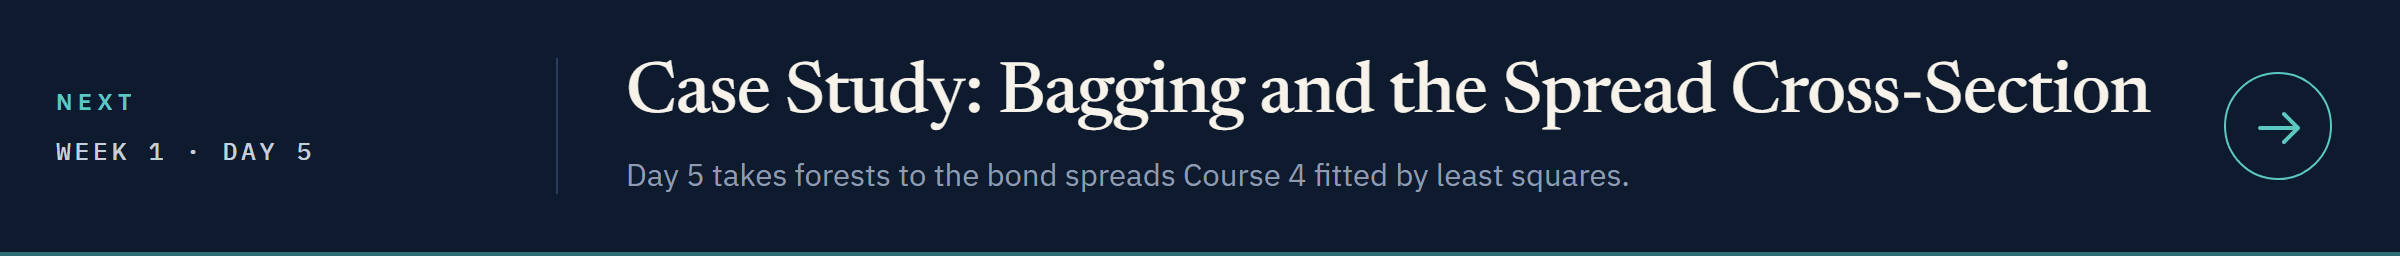](../day5/05_case_study_bagging_and_the_spread_cross_section.ipynb)

[Open Day 5 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week1/day5/05_case_study_bagging_and_the_spread_cross_section.ipynb)